# 02 · Member 2 analysis: Routing, Duration, FX conversions
**Owner:** Ong Wan Ning · **Needs:** run `04_integration_validation.ipynb` first.

For each rule: write the hypothesis → test it on the full data → chart it with the rule as its title → save it to `outputs/` → add a row to `outputs/tables/rules/rules_02.csv` → run `combine_rules()`.

**Scope of this notebook**
- `TRANSACTION_TYPE_CODE` (Direct / Indirect / Covered) **is** the routing type, so routing and transaction type form one group.
- Builds on, does not repeat: R-CCY2 / R-CCY3 (FX), R-BC2 (timing), N4 (type/hour → amount, rejected).
- Every `save_table()` output in `outputs/tables/` is small and aggregated: import **these** into Power BI, not the parquet.

In [23]:
from pathlib import Path
import os, warnings; warnings.filterwarnings('ignore')
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW, PROC = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed'
FIG, TAB = ROOT / 'outputs' / 'figures', ROOT / 'outputs' / 'tables'
RULES = TAB / 'rules'                       # one rules file per notebook -> combined into outputs/tables/rules_log.csv
for d in (RAW, PROC, FIG, TAB, RULES): d.mkdir(parents=True, exist_ok=True)
FULL    = PROC / 'payments_clean.parquet'   # all 10M rows (nothing removed) + derived columns, built by notebook 04
SAMPLE  = PROC / 'sample_20pct.parquet'     # 20% Bernoulli sample (seed 42), no free-text columns, still includes anomalies
ANOM    = PROC / 'anomalies.parquet'        # every labelled anomaly row, all columns
SCHEMA_VERSION = '2'                        # bump when derived columns change -> notebook 04 rebuilds the files

def connect(db=':memory:'):
    con = duckdb.connect(str(db))
    con.execute("SET TimeZone='UTC'")       # never skip: otherwise DuckDB shows laptop time (+08)
    con.execute("SET preserve_insertion_order=false")
    try: con.execute("SET enable_progress_bar=false")   # no progress widgets saved in the notebook ("Could not render ... widget" in viewers)
    except Exception: pass                           # (older setups without ipywidgets show no widget anyway)
    con.execute(f"SET temp_directory='{(PROC / 'duck_tmp').as_posix()}'")   # big joins spill to disk instead of crashing
    if os.environ.get('SWIFT_MEMORY'):  con.execute(f"SET memory_limit='{os.environ['SWIFT_MEMORY']}'")   # e.g. 4GB on an 8 GB laptop
    if os.environ.get('SWIFT_THREADS'): con.execute(f"SET threads={int(os.environ['SWIFT_THREADS'])}")
    return con

In [24]:
con = connect()

In [25]:
def sql(q):
    """Run SQL on the full data and return a pandas DataFrame."""
    return con.execute(q).df()
q = sql
def save_table(df, name):
    """Save a result table to outputs/tables/<name>.csv and return it for display."""
    df.to_csv(TAB / f'{name}.csv', index=False); return df

RULE_COLS = ['id', 'group', 'rule', 'test', 'value', 'verdict', 'evidence_files', 'interpretation']
VERDICTS = 'Confirmed (holds in >=99% of rows / effect matches) · Strong (95-99%) · Partial (70-95% or only in a subgroup) · Rejected'
def verdict_from_share(x):
    return 'Confirmed' if x >= 0.99 else 'Strong' if x >= 0.95 else 'Partial' if x >= 0.70 else 'Rejected'

def combine_rules():
    """Merge every outputs/tables/rules/rules_*.csv into one outputs/tables/rules_log.csv (shared schema)."""
    frames = []
    for f in sorted(RULES.glob('rules_*.csv')):
        d = pd.read_csv(f)
        ren = {'observed_evidence_table_or_chart': 'evidence_files', 'interpretation_real_world': 'interpretation', 'confidence': 'verdict'}
        d = d.rename(columns={k: v for k, v in ren.items() if k in d.columns and v not in d.columns})
        if 'rule' not in d.columns and {'when_condition', 'then_effect'} <= set(d.columns):
            d['rule'] = d.when_condition.astype(str) + ' -> ' + d.then_effect.astype(str)
        if 'value' not in d.columns and 'size' in d.columns: d['value'] = d['size']
        d['source'] = f.name; frames.append(d)
    if not frames: return pd.DataFrame(columns=RULE_COLS)
    out = pd.concat(frames, ignore_index=True)
    out = out[[c for c in RULE_COLS + ['source'] if c in out.columns] + [c for c in out.columns if c not in RULE_COLS + ['source']]]
    out.to_csv(TAB / 'rules_log.csv', index=False); return out

In [26]:
# Main view `p` = full data with the shared derived columns (see notebook 04, section 1)
assert FULL.exists() and (PROC / '_schema_version.txt').exists() and (PROC / '_schema_version.txt').read_text().strip() == SCHEMA_VERSION, \
    'Shared data missing or outdated: run notebooks/04_integration_validation.ipynb first'
con.execute(f"CREATE OR REPLACE VIEW p AS SELECT * FROM read_parquet('{FULL.as_posix()}')")
# Local currency of each BIC country = the currency its senders use most (inferred from this dataset, no external lookup)
con.execute("""CREATE OR REPLACE TABLE local_ccy AS
  SELECT o_cc AS cc, arg_max(CURRENCY_CODE, n) AS local_ccy FROM
  (SELECT o_cc, CURRENCY_CODE, count(*) n FROM p GROUP BY ALL) GROUP BY o_cc""")
print(f"{con.execute('SELECT count(*) FROM p').fetchone()[0]:,} payments loaded")

10,000,000 payments loaded


In [27]:
# Sender-country time zone (one zone per country; multi-zone countries such as US/RU/CA/AU/BR are approximate, same as R-BC2).
# If notebook 01 already has its own country -> time zone table, swap it in here so both notebooks agree.
import pytz
ccs = sql("SELECT DISTINCT o_cc AS cc FROM p UNION SELECT DISTINCT b_cc FROM p").cc
tz = pd.DataFrame({'cc': ccs, 'tz': [pytz.country_timezones.get(c, ['UTC'])[0] for c in ccs]})
print('countries without a time zone (UTC used):', sorted(set(ccs) - set(pytz.country_timezones)))
con.register('tz_df', tz); con.execute("CREATE OR REPLACE TABLE tz AS SELECT * FROM tz_df")

# pl = full data + sender-local hour and ISO weekday (1 = Mon ... 7 = Sun)
con.execute("""CREATE OR REPLACE VIEW pl AS
  SELECT p.*, hour(timezone(coalesce(z.tz,'UTC'), to_timestamp(p.EPOCH_SECONDS)))  AS local_hour,
              isodow(timezone(coalesce(z.tz,'UTC'), to_timestamp(p.EPOCH_SECONDS))) AS local_wd
  FROM p LEFT JOIN tz z ON p.o_cc = z.cc""")

# Pandas sample for charts / models (includes anomalies; sn = normal payments only)
s = sql(f"""SELECT s.*, hour(timezone(coalesce(z.tz,'UTC'), to_timestamp(s.EPOCH_SECONDS)))  AS local_hour,
                       isodow(timezone(coalesce(z.tz,'UTC'), to_timestamp(s.EPOCH_SECONDS))) AS local_wd
            FROM read_parquet('{SAMPLE.as_posix()}') s LEFT JOIN tz z ON s.o_cc = z.cc""")
s['ly'] = np.log(s.TOTAL_DURATION)
sn = s[s.anomaly == 'NONE'].copy()
print(f'sample: {len(s):,} rows, normal: {len(sn):,}')

def r2(df, cols, y='ly'):
    """Share of variance in y explained by the group means of cols (eta squared)."""
    cols = [cols] if isinstance(cols, str) else list(cols)
    g = df.groupby(cols, observed=True)[y].transform('mean')
    return 1 - ((df[y] - g) ** 2).sum() / ((df[y] - df[y].mean()) ** 2).sum()

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f'{name}.png', dpi=200, bbox_inches='tight'); plt.show()

TYPES = ['Direct', 'Indirect', 'Covered']

def cramers_v(t):
    """Cramér's V of a contingency table of counts (0 = independent)."""
    t = np.asarray(t, float); e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
    return float(np.sqrt(((t - e) ** 2 / e).sum() / (t.sum() * (min(t.shape) - 1))))

def additive_r2(df, cols, y='ly', iters=10):
    """R² of an additive model y ~ effect[col1] + effect[col2] + ... (backfitting; no interaction cells)."""
    r = df[y] - df[y].mean()
    eff = {c: pd.Series(0.0, index=df.index) for c in cols}
    for _ in range(iters):
        for c in cols:
            part = r + eff[c]
            eff[c] = part.groupby(df[c], observed=True).transform('mean')
            r = part - eff[c]
    return 1 - (r ** 2).sum() / ((df[y] - df[y].mean()) ** 2).sum()

countries without a time zone (UTC used): ['XK']
sample: 2,001,857 rows, normal: 2,000,484


## Feature group: Routing (`TRANSACTION_TYPE_CODE`)
**Hypotheses**
- H-RT1: Direct payments always have exactly 2 participants; Indirect and Covered add intermediary banks.
- H-RT2: The path starts at the ordering BIC and ends at the beneficiary BIC.
- H-RT3: Once the `...` gap and repeated BICs are removed, the number of distinct banks on the path equals `PARTICIPANT_COUNT`.
- H-RT4: The routing type depends on whether the payment is cross-border, on the B/C pair, or on anomalies.

In [28]:
# H-RT1: hop count by routing type
rt1 = save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, PARTICIPANT_COUNT, count(*) n,
       round(100.0 * count(*) / sum(count(*)) OVER (PARTITION BY TRANSACTION_TYPE_CODE), 2) pct
FROM p GROUP BY 1, 2 ORDER BY 1, 2"""), 'rt1_hops_by_type')
rt1_share = sql("SELECT avg(((TRANSACTION_TYPE_CODE = 'Direct') = (PARTICIPANT_COUNT = 2))::INT) FROM p").iloc[0, 0]
print(f'Direct <=> 2 participants holds in {rt1_share:.4%} of rows')
rt1.pivot(index='PARTICIPANT_COUNT', columns='TRANSACTION_TYPE_CODE', values='pct').fillna(0)

Direct <=> 2 participants holds in 100.0000% of rows


TRANSACTION_TYPE_CODE,Covered,Direct,Indirect
PARTICIPANT_COUNT,,,
2,0.00,100.0,0.00
3,63.24,0.0,63.21
4,23.22,0.0,23.27
5,8.56,0.0,8.54
6,3.14,0.0,3.15
7,1.16,0.0,1.16
8,0.43,0.0,0.42
9,0.16,0.0,0.16
10,0.06,0.0,0.06


In [29]:
# H-RT2 / H-RT3: path endpoints and path length vs PARTICIPANT_COUNT
rt2 = save_table(sql("""
WITH x AS (SELECT TRANSACTION_TYPE_CODE, path_gap, path_len, PARTICIPANT_COUNT, ORDERING_BIC8, BENEFICIARY_BIC8,
                  string_split(BIC8_PATH, ';') AS l FROM p)
SELECT TRANSACTION_TYPE_CODE, path_gap, count(*) n,
       avg((l[1] = ORDERING_BIC8)::INT)        AS starts_at_ordering_bic,
       avg((l[-1] = BENEFICIARY_BIC8)::INT)    AS ends_at_beneficiary_bic,
       avg((path_len = PARTICIPANT_COUNT)::INT) AS path_len_eq_participants,
       avg((len(list_distinct(list_filter(l, lambda b: b <> '...'))) = PARTICIPANT_COUNT)::INT) AS distinct_banks_eq_participants,
       avg((len(list_filter(l, lambda b: b <> '...')) > len(list_distinct(list_filter(l, lambda b: b <> '...'))))::INT) AS has_repeated_bic
FROM x GROUP BY 1, 2 ORDER BY 1, 2"""), 'rt2_path_vs_participants')
w = lambda col, mask=slice(None): np.average(rt2.loc[mask, col], weights=rt2.loc[mask, 'n'])
rt2_start, rt2_end = w('starts_at_ordering_bic'), w('ends_at_beneficiary_bic')
rt3_share = w('distinct_banks_eq_participants', ~rt2.path_gap)
print(f'path starts at ordering BIC {rt2_start:.2%}, ends at beneficiary BIC {rt2_end:.2%}; '
      f'distinct banks = participants (no gap) {rt3_share:.2%}')
rt2

path starts at ordering BIC 95.02%, ends at beneficiary BIC 95.01%; distinct banks = participants (no gap) 99.47%


,TRANSACTION_TYPE_CODE,path_gap,n,starts_at_ordering_bic,ends_at_beneficiary_bic,path_len_eq_participants,distinct_banks_eq_participants,has_repeated_bic
0,Covered,False,364700,0.950688,0.949737,1.0,0.973770,2.622978e-02
1,Covered,True,51262,0.950646,0.951446,0.0,0.964360,3.564044e-02
2,Direct,False,6008014,0.950148,0.950008,1.0,0.999999,9.986661e-07
3,Direct,True,315266,0.950718,0.950220,0.0,1.000000,0.000000e+00
4,Indirect,False,2860082,0.950020,0.950201,1.0,0.986149,1.385135e-02
5,Indirect,True,400676,0.950354,0.950157,0.0,0.979594,2.040551e-02


In [30]:
# H-RT2 follow-up: when the path does NOT start at the ordering BIC, which country does it start in?
save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, cross_border,
       substr(string_split(BIC8_PATH, ';')[1], 5, 2) = o_cc AS first_bank_same_country,
       count(*) n
FROM p WHERE string_split(BIC8_PATH, ';')[1] <> ORDERING_BIC8
GROUP BY ALL ORDER BY n DESC LIMIT 20"""), 'rt2_first_bank_mismatch')

,TRANSACTION_TYPE_CODE,cross_border,first_bank_same_country,n
0,Direct,True,False,284559
1,Indirect,True,False,146854
2,Covered,True,False,18732
3,Direct,False,False,15258
4,Direct,True,True,12782
5,Indirect,False,False,8095
6,Indirect,True,True,6698
7,Direct,False,True,2448
8,Indirect,False,True,1191
9,Covered,False,False,826


In [31]:
# H-RT5: the '...' gap. Is there an independent ~5% chance of a gap on every link between two consecutive banks?
rt5 = sql("""SELECT PARTICIPANT_COUNT, count(*) n, avg(path_gap::INT) gap_rate
             FROM p GROUP BY 1 HAVING count(*) >= 1000 ORDER BY 1""")
q_link = rt5.loc[rt5.PARTICIPANT_COUNT == 2, 'gap_rate'].iloc[0]          # Direct = 1 link -> per-link gap chance
rt5['predicted_per_link'] = 1 - (1 - q_link) ** (rt5.PARTICIPANT_COUNT - 1)
rt5_maxerr = (rt5.gap_rate - rt5.predicted_per_link).abs().max()
save_table(rt5, 'rt5_gap_by_participants')
print(f"per-link gap chance {q_link:.4f}; largest gap between observed and predicted rate: {rt5_maxerr:.4f}")
rt5

per-link gap chance 0.0499; largest gap between observed and predicted rate: 0.0139


,PARTICIPANT_COUNT,n,gap_rate,predicted_per_link
0,2,6323280,0.049858,0.049858
1,3,2324319,0.097410,0.097230
2,4,855386,0.142464,0.142240
3,5,314014,0.184957,0.185007
4,6,115701,0.225270,0.225641
5,7,42622,0.269274,0.264249
6,8,15481,0.308378,0.300932
7,9,5758,0.330497,0.335786
8,10,2205,0.382766,0.368902


In [32]:
# H-RT6: number of intermediary banks is geometric (each further intermediary added with the same chance q)
rt6 = sql("SELECT PARTICIPANT_COUNT - 2 AS intermediaries, count(*) n FROM p GROUP BY 1 ORDER BY 1")
rt6['share'] = rt6.n / rt6.n.sum()
q_hop = 1 - rt6.share.iloc[0]                                              # chance of at least one more intermediary
rt6['predicted'] = (1 - q_hop) * q_hop ** rt6.intermediaries
rt6['ratio_to_previous'] = rt6.share / rt6.share.shift()
rt6_tvd = 0.5 * (rt6.share - rt6.predicted).abs().sum()                   # total variation distance, 0 = identical
save_table(rt6, 'rt6_intermediaries_geometric')
print(f"q = {q_hop:.4f} (1/e = {np.exp(-1):.4f}); distance observed vs geometric = {rt6_tvd:.4f}")
rt6.head(10)

q = 0.3677 (1/e = 0.3679); distance observed vs geometric = 0.0001


,intermediaries,n,share,predicted,ratio_to_previous
0,0,6323280,0.632328,0.632328,NaN
1,1,2324319,0.232432,0.232489,0.367581
2,2,855386,0.085539,0.085480,0.368016
3,3,314014,0.031401,0.031429,0.367102
4,4,115701,0.011570,0.011555,0.368458
5,5,42622,0.004262,0.004249,0.368381
6,6,15481,0.001548,0.001562,0.363216
7,7,5758,0.000576,0.000574,0.371940
8,8,2205,0.000220,0.000211,0.382945
9,9,769,0.000077,0.000078,0.348753


In [33]:
# Lead for the currency teammate (R-CCY1): is the payment currency the local currency of the FIRST BANK ON THE PATH
# (which differs from the ordering BIC in ~5% of rows) rather than of the ordering BIC?
lead = sql("""
SELECT (string_split(BIC8_PATH, ';')[1] = ORDERING_BIC8) AS path_starts_at_ordering_bic, count(*) n,
       avg((CURRENCY_CODE = lo.local_ccy)::INT) AS ccy_is_ordering_country_local,
       avg((CURRENCY_CODE = lf.local_ccy)::INT) AS ccy_is_first_bank_local
FROM p LEFT JOIN local_ccy lo ON p.o_cc = lo.cc
       LEFT JOIN local_ccy lf ON substr(string_split(p.BIC8_PATH, ';')[1], 5, 2) = lf.cc
GROUP BY 1""")
save_table(lead, 'rt2_currency_vs_first_bank')

,path_starts_at_ordering_bic,n,ccy_is_ordering_country_local,ccy_is_first_bank_local
0,True,9501601,0.934126,0.934126
1,False,498399,0.138638,0.934757


In [34]:
# H-RT4: does routing type depend on cross-border / B-C pair / anomaly?  (row % within each group + Cramér's V)
rt4, rt4_v = {}, {}
for col in ['cross_border', 'pair', 'anomaly']:
    d = sql(f"""SELECT {col}::VARCHAR AS grp, TRANSACTION_TYPE_CODE t, count(*) n FROM p GROUP BY 1, 2""")
    t = d.pivot(index='grp', columns='t', values='n').fillna(0)
    rt4_v[col] = cramers_v(t)
    rt4[col] = (t.div(t.sum(1), axis=0) * 100).round(2).assign(n=t.sum(1))
    save_table(rt4[col].reset_index(), f'rt4_type_by_{col}')
    print(f"{col}: Cramér's V = {rt4_v[col]:.4f}"); display(rt4[col])
cov_dom, cov_xb = rt4['cross_border'].loc['false', 'Covered'], rt4['cross_border'].loc['true', 'Covered']

cross_border: Cramér's V = 0.0459


t,Covered,Direct,Indirect,n
grp,,,,
false,7.34,63.25,29.41,711116
true,3.92,63.23,32.85,9288884


pair: Cramér's V = 0.0024


t,Covered,Direct,Indirect,n
grp,,,,
B2B,4.09,63.22,32.69,2270945
B2C,4.22,63.23,32.55,5603692
C2B,4.08,63.19,32.73,610605
C2C,4.08,63.28,32.64,1514758


anomaly: Cramér's V = 0.0032


t,Covered,Direct,Indirect,n
grp,,,,
ACCOUNT_REPLACEMENT_SCAM,0.46,68.26,31.28,649
CEO_SCAM,0.74,62.65,36.61,945
CUSTOMER_RECALL,4.73,58.99,36.28,317
DUPLICATE_PAYMENT,4.57,60.09,35.35,679
FAT_FINGER_MISTAKE,4.54,65.52,29.95,1940
NONE,4.16,63.23,32.61,9992994
ROMANCE_SCAM,0.12,60.34,39.54,2476


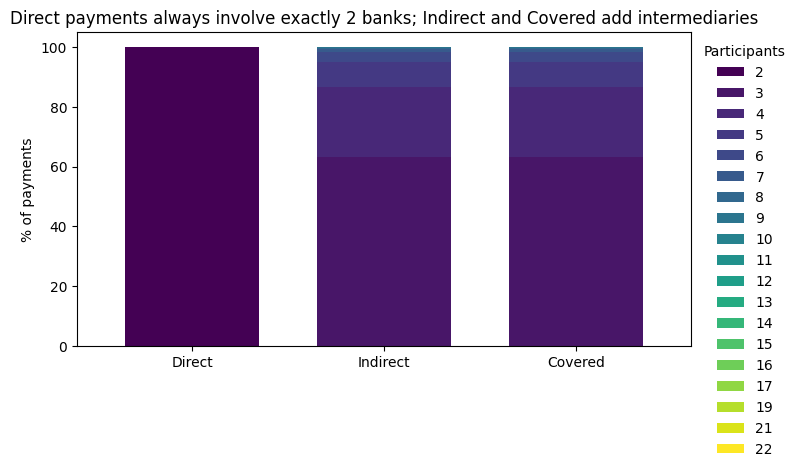

In [35]:
# Chart: hop count by routing type
d = rt1.pivot(index='PARTICIPANT_COUNT', columns='TRANSACTION_TYPE_CODE', values='pct').fillna(0)[TYPES]
ax = d.T.plot.bar(stacked=True, figsize=(8, 4.5), colormap='viridis', width=0.7)
ax.set_title(f'Direct payments always involve exactly 2 banks; Indirect and Covered add intermediaries')
ax.set_xlabel(''); ax.set_ylabel('% of payments'); ax.legend(title='Participants', bbox_to_anchor=(1, 1), frameon=False)
plt.xticks(rotation=0); savefig('rt1_hops_by_type')

**Findings (Routing)** (numbers from the full 10M rows; ⟳ = value is printed by a cell above, check it after the run)
- **R-RT1 Direct = exactly 2 banks** (100%). Indirect and Covered always have ≥ 3. *Meaning:* a Direct payment needs a bilateral account between the two banks; otherwise correspondent banks relay it.
- **R-RT6 Number of intermediaries is geometric:** 63.2% have none (Direct), 23.2% one, 8.6% two, 3.1% three … each extra intermediary is ~0.37× as common as the one before (⟳ `q`, distance to the geometric model). Indirect and Covered have the **same** hop distribution. *Meaning:* banks use the shortest correspondent chain available; long chains are rare.
- **R-RT3 `PARTICIPANT_COUNT` = number of BIC entries on the path, repeats counted** (100% of complete paths). A BIC appears twice in 1.4% of Indirect and 2.6% of Covered paths, never in Direct.
- **R-RT2 The path starts at the ordering BIC and ends at the beneficiary BIC in 95.0% of rows** (each end), the same for every routing type. When the first bank differs, it is usually in another country. *Meaning:* a parent/branch BIC or an outsourced sending bank. ⟳ Check `rt2_currency_vs_first_bank`: if the payment currency follows the first bank, this explains part of R-CCY1's exceptions → tell the currency teammate.
- **R-RT5 The `...` gap:** 5.0% of Direct vs 12.3% of Indirect/Covered paths, consistent with an independent ~5% chance per link (⟳ largest error vs that model).
- **R-RT7 Routing type is independent of the B/C pair:** Direct 63.2% in B2B, B2C, C2B and C2C alike (⟳ Cramér's V).
- **R-RT8 Domestic payments are routed Covered almost twice as often:** 7.3% vs 3.9% cross-border; the Direct share is identical (63.2%). *Counter-intuitive:* in practice the cover method is used for cross-border payments, so flag it as a data-generation feature.
- **For Member 3 (anomalies):** scams are almost never Covered: romance 0.12%, CEO 0.74%, account-replacement 0.46% vs 4.16% for normal payments.

## Feature group: Duration (`TOTAL_DURATION`)
**Hypotheses**
- H-DUR1: Duration depends on the routing type (Direct < Indirect < Covered).
- H-DUR2: Within each routing type, every extra participant adds time.
- H-DUR3: Sender-local hour / weekday changes duration (e.g. payments sent after hours or at weekends wait longer).
- H-DUR4: Amount, B/C pair, cross-border and anomaly have no extra effect once routing is known.

In [36]:
# H-DUR1 / H-DUR2: duration by routing type and hop count (full data)
dur1 = save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, PARTICIPANT_COUNT, count(*) n,
       median(TOTAL_DURATION) med, quantile_cont(TOTAL_DURATION, 0.1) p10, quantile_cont(TOTAL_DURATION, 0.9) p90,
       exp(avg(ln(TOTAL_DURATION))) geo_mean
FROM p WHERE anomaly = 'NONE' GROUP BY 1, 2 ORDER BY 1, 2"""), 'dur1_by_type_hops')
med_type = sql("SELECT TRANSACTION_TYPE_CODE t, median(TOTAL_DURATION) med FROM p WHERE anomaly='NONE' GROUP BY 1").set_index('t').med
print(med_type.round(0).to_dict())
dur1

{'Direct': 39.0, 'Covered': 383.0, 'Indirect': 281.0}


,TRANSACTION_TYPE_CODE,PARTICIPANT_COUNT,n,med,p10,p90,geo_mean
0,Covered,3,262970,288.0,22.0,2517.0,213.755542
1,Covered,4,96538,445.0,31.0,2913.0,325.829023
2,Covered,5,35574,587.0,43.0,3352.0,468.219584
3,Covered,6,13079,752.0,55.0,3618.8,608.448929
4,Covered,7,4823,941.0,69.0,4040.4,761.469685
5,Covered,8,1768,1130.0,96.7,4327.7,928.416625
6,Covered,9,685,1413.0,183.2,4633.2,1143.432475
7,Covered,10,238,1807.0,253.6,4830.8,1306.959446
8,Covered,11,92,1893.0,237.1,5185.3,1514.752530
9,Covered,12,30,1385.5,622.1,4264.0,1498.194288


In [37]:
# Factor screening on ln(duration): R² alone, and extra R² on top of routing type + hops
sn['amt_decile'] = pd.qcut(np.log(sn.USD_AMOUNT), 10, labels=False)
base = ['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT']
r2_base = r2(sn, base)
cands = ['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT', 'CURRENCY_CONVERSION_COUNT', 'path_gap', 'cross_border',
         'pair', 'local_hour', 'local_wd', 'o_cc', 'b_cc', 'amt_decile']
dur_r2 = pd.DataFrame({'r2_alone': {c: r2(sn, c) for c in cands},
                       'extra_r2_given_type_hops': {c: (r2(sn, base + [c]) - r2_base) if c not in base else np.nan for c in cands}}
                      ).sort_values('r2_alone', ascending=False).round(4)
print(f'R² of routing type + hops together: {r2_base:.3f}')
save_table(dur_r2.reset_index(names='factor'), 'dur2_factor_screening')

R² of routing type + hops together: 0.046


,factor,r2_alone,extra_r2_given_type_hops
0,PARTICIPANT_COUNT,0.0462,NaN
1,o_cc,0.0418,0.0448
2,CURRENCY_CONVERSION_COUNT,0.0390,0.0004
3,b_cc,0.0386,0.0413
4,TRANSACTION_TYPE_CODE,0.0344,NaN
5,path_gap,0.0012,0.0000
6,amt_decile,0.0006,0.0007
7,cross_border,0.0006,0.0007
8,pair,0.0000,0.0001
9,local_hour,0.0000,0.0001


In [38]:
# Anomalies: do anomalous payments take longer than normal ones with the same routing?
save_table(sql("""
SELECT anomaly, count(*) n, median(TOTAL_DURATION) med,
       median(TOTAL_DURATION / PARTICIPANT_COUNT) med_per_participant
FROM p GROUP BY 1 ORDER BY med DESC"""), 'dur4_by_anomaly')

,anomaly,n,med,med_per_participant
0,ROMANCE_SCAM,2476,1148.0,473.5
1,CEO_SCAM,945,741.0,270.5
2,ACCOUNT_REPLACEMENT_SCAM,649,571.0,234.5
3,DUPLICATE_PAYMENT,679,261.0,115.5
4,NONE,9992994,56.0,23.0
5,FAT_FINGER_MISTAKE,1940,53.0,22.5
6,CUSTOMER_RECALL,317,53.0,22.5


In [39]:
# H-DUR2: sender and receiver country (Direct payments only, so routing is fixed). Additive model, no interaction.
dd = sn[sn.TRANSACTION_TYPE_CODE == 'Direct']
dur_cc = pd.Series({'sender country': r2(dd, 'o_cc'), 'receiver country': r2(dd, 'b_cc'),
                    'sender + receiver (additive)': additive_r2(dd, ['o_cc', 'b_cc'])}).round(4)
print(dur_cc)
cc_speed = sql("""SELECT o_cc AS country, count(*) n, median(TOTAL_DURATION) med_duration_as_sender
                  FROM p WHERE anomaly = 'NONE' AND TRANSACTION_TYPE_CODE = 'Direct' GROUP BY 1 HAVING count(*) >= 5000
                  ORDER BY med_duration_as_sender""")
save_table(cc_speed, 'dur2_country_speed_direct')
pd.concat([cc_speed.head(5).assign(rank='fastest'), cc_speed.tail(5).assign(rank='slowest')])

sender country                  0.0505
receiver country                0.0466
sender + receiver (additive)    0.0913
dtype: float64


,country,n,med_duration_as_sender,rank
0,UG,7161,21.0,fastest
1,PY,8527,22.0,fastest
2,SX,7469,23.0,fastest
3,LI,37143,23.0,fastest
4,DO,5872,24.0,fastest
93,BR,13566,1631.0,slowest
94,AO,5001,1659.0,slowest
95,LB,9450,1825.0,slowest
96,SK,5134,2130.0,slowest
97,HR,6364,3119.0,slowest


In [40]:
# H-DUR3: duration by sender-local hour and weekday (normal payments)
dur3 = save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, local_hour, count(*) n, median(TOTAL_DURATION) med
FROM pl WHERE anomaly = 'NONE' GROUP BY 1, 2 ORDER BY 1, 2"""), 'dur3_by_local_hour')
dur3w = save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, local_wd, count(*) n, median(TOTAL_DURATION) med
FROM pl WHERE anomaly = 'NONE' GROUP BY 1, 2 ORDER BY 1, 2"""), 'dur3_by_local_weekday')
dur3w.pivot(index='local_wd', columns='TRANSACTION_TYPE_CODE', values='med')[TYPES]

TRANSACTION_TYPE_CODE,Direct,Indirect,Covered
local_wd,,,
1,39.0,282.0,382.0
2,39.0,280.0,383.0
3,39.0,276.0,387.0
4,39.0,282.0,381.0
5,39.0,281.0,382.0
6,39.0,286.0,379.0
7,39.0,282.0,378.0


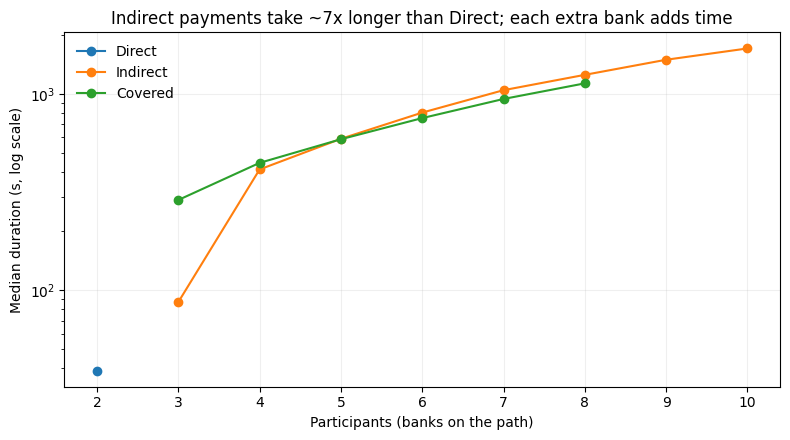

In [41]:
# Chart 1: duration by routing type and hops
fig, ax = plt.subplots(figsize=(8, 4.5))
for t in TYPES:
    d = dur1[(dur1.TRANSACTION_TYPE_CODE == t) & (dur1.n >= 1000)]
    ax.plot(d.PARTICIPANT_COUNT, d.med, marker='o', label=t)
ax.set_yscale('log'); ax.set_xlabel('Participants (banks on the path)'); ax.set_ylabel('Median duration (s, log scale)')
ratio = med_type.get('Indirect', np.nan) / med_type.get('Direct', np.nan)
ax.set_title(f'Indirect payments take ~{ratio:.0f}x longer than Direct; each extra bank adds time')  # check against the data
ax.legend(frameon=False); ax.grid(alpha=0.2); savefig('dur1_by_type_hops')

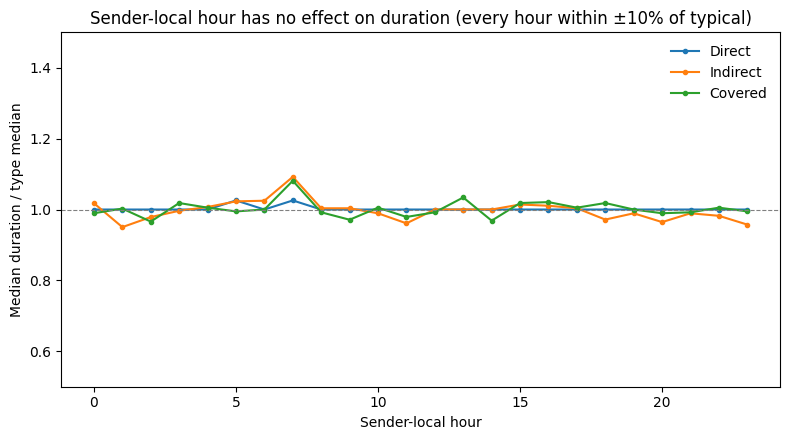

In [42]:
# Chart 2: duration by sender-local hour (baseline = each routing type's own median); fixed y-range so noise is not magnified
d = dur3.pivot(index='local_hour', columns='TRANSACTION_TYPE_CODE', values='med')[TYPES]
ax = (d / d.median()).plot(figsize=(8, 4.5), marker='.')
ax.axhline(1, color='grey', lw=0.8, ls='--'); ax.set_ylim(0.5, 1.5)
ax.set_title('Sender-local hour has no effect on duration (every hour within ±10% of typical)')
ax.set_xlabel('Sender-local hour'); ax.set_ylabel('Median duration / type median'); ax.legend(frameon=False)
savefig('dur3_by_local_hour')

**Findings (Duration)** (normal payments; ⟳ = check the printed value)
- **R-DUR1 Routing sets the speed:** median Direct 39 s, Indirect 281 s (~7×), Covered 383 s (~10×). Within Indirect and Covered, every extra bank adds roughly 150–250 s (median 412 s at 4 banks → 1,043 s at 7). Covered is slower than Indirect only at 3 banks (288 vs 87 s); from 4 banks on they are the same. *But* duration is very noisy: routing explains only 4.6% of the variance of ln(duration), and even Direct payments have a p90 of 2,343 s.
- **R-DUR2 Country matters as much as routing:** sender and receiver country each add ~0.04 R² on top of routing (⟳ Direct-only additive R², fastest/slowest countries table). *Meaning:* each country's banks have their own processing speed (cut-offs, compliance checks).
- **R-DUR3 Scam payments take 10–20× longer:** median romance 1,148 s, CEO 741 s, account-replacement 571 s, duplicates 261 s vs 56 s normal. Fat-finger and customer-recall payments are as fast as normal (53 s). The gap remains per bank (473 vs 23 s per participant), so it is not just longer routes. *Meaning:* suspicious payments are held for screening. → share with Member 3.
- **N-DUR1 Sender-local hour and weekday have no effect** (extra R² 0.0001 and 0.0000; weekday medians identical within 2%).

## Feature group: FX conversions (`CURRENCY_CONVERSION_COUNT`)
Extends R-CCY2 (Direct, 97.8%) and R-CCY3 (conversions ≤ hops, 100%).

**Hypotheses**
- H-FX1: Conversions = the number of currency changes along the chain *payment currency → local currency of each bank on the path*.
  (Alternative H-FX1b: only changes between consecutive banks' local currencies, ignoring the payment currency.)
- H-FX2: At the same routing type and hop count, every conversion adds duration.

In [43]:
# Conversions by routing type and hop count (full data)
fx1 = save_table(sql("""
SELECT TRANSACTION_TYPE_CODE, PARTICIPANT_COUNT, CURRENCY_CONVERSION_COUNT, count(*) n, median(TOTAL_DURATION) med_dur
FROM p GROUP BY ALL ORDER BY ALL"""), 'fx1_conv_by_hops')
fx1.pivot_table(index=['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT'], columns='CURRENCY_CONVERSION_COUNT', values='n', fill_value=0)

CURRENCY_CONVERSION_COUNT                      0          1          2         3         4        5        6       7       8      9      10    11    12   13   14   15   16   17
TRANSACTION_TYPE_CODE PARTICIPANT_COUNT                                                                                                                                         
Covered               3                   13500.0    53430.0   196133.0       0.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      4                    1324.0     5749.0    29169.0   60328.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      5                     117.0      576.0     3896.0   11616.0   19385.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      6                      11.0       71.0      474.0    1756.0    4704.0   6064.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      7                       3.0        7.0       58.0     230.0     815.0   1767.0   1945.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      8                       1.0        0.0        5.0      26.0     140.0    331.0    643.0   624.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      9                       0.0        0.0        1.0       7.0      13.0     63.0    164.0   242.0   195.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      10                      0.0        0.0        0.0       0.0       4.0      8.0     30.0    54.0    88.0   55.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      11                      0.0        0.0        0.0       0.0       0.0      2.0      4.0    14.0    22.0   28.0   22.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      12                      0.0        0.0        0.0       0.0       0.0      0.0      1.0     2.0     4.0    7.0   10.0   6.0   0.0  0.0  0.0  0.0  0.0  0.0
                      13                      0.0        0.0        0.0       0.0       0.0      0.0      0.0     0.0     1.0    2.0    1.0   2.0   2.0  0.0  0.0  0.0  0.0  0.0
                      14                      0.0        0.0        0.0       0.0       0.0      0.0      0.0     0.0     0.0    1.0    1.0   1.0   4.0  1.0  0.0  0.0  0.0  0.0
                      15                      0.0        0.0        0.0       0.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   2.0  0.0  0.0  0.0  0.0  0.0
Direct                2                  991870.0  5331410.0        0.0       0.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
Indirect              3                   71789.0   451686.0  1537781.0       0.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      4                    7092.0    47223.0   218932.0  485569.0       0.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      5                     736.0     5067.0    27586.0   91388.0  153647.0      0.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      6                      84.0      538.0     3483.0   13555.0   36016.0  48945.0      0.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      7                       4.0       75.0      417.0    1839.0    6265.0  13594.0  15603.0     0.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      8                       0.0        8.0       52.0     262.0     911.0   2690.0   4951.0  4837.0     0.0    0.0    0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0
                      9                       0.0        0.0        5.0      27.0     129.0    417.0   109

In [44]:
# H-FX1: predict conversions from the path (20% sample, rows without the '...' gap)
# local currency of a bank = local_ccy of its BIC country (letters 5-6); banks in countries with no senders are unmapped
con.execute(f"CREATE OR REPLACE VIEW sp AS SELECT * FROM read_parquet('{SAMPLE.as_posix()}')")
fx_pred = sql("""
WITH s AS (SELECT rid, BIC8_PATH, CURRENCY_CODE FROM sp WHERE NOT path_gap),
h AS (SELECT rid, unnest(l) AS bic, unnest(range(1, len(l) + 1)) AS pos
      FROM (SELECT rid, string_split(BIC8_PATH, ';') AS l FROM s)),
seq AS (SELECT h.rid, h.pos, c.local_ccy AS ccy FROM h LEFT JOIN local_ccy c ON substr(h.bic, 5, 2) = c.cc
        UNION ALL SELECT rid, 0, CURRENCY_CODE FROM s),
chg AS (SELECT rid, pos, ccy, lag(ccy) OVER (PARTITION BY rid ORDER BY pos) AS prev FROM seq)
SELECT rid, bool_or(ccy IS NULL) AS unmapped,
       sum(CASE WHEN pos >= 1 AND ccy <> prev THEN 1 ELSE 0 END) AS pred_with_payccy,
       sum(CASE WHEN pos >= 2 AND ccy <> prev THEN 1 ELSE 0 END) AS pred_banks_only
FROM chg GROUP BY rid""")
con.register('fx_pred_df', fx_pred)
fx2 = save_table(sql("""
SELECT coalesce(TRANSACTION_TYPE_CODE, 'ALL') AS type, count(*) n,
       avg((pred_with_payccy = CURRENCY_CONVERSION_COUNT)::INT) AS acc_with_payment_ccy,
       avg((pred_banks_only  = CURRENCY_CONVERSION_COUNT)::INT) AS acc_banks_only
FROM sp JOIN fx_pred_df USING (rid) WHERE NOT unmapped
GROUP BY ROLLUP (TRANSACTION_TYPE_CODE) ORDER BY n DESC"""), 'fx2_conversion_prediction')
print(f"unmapped rows skipped: {fx_pred.unmapped.mean():.2%}")
fx_acc     = fx2.set_index('type').loc['ALL', 'acc_with_payment_ccy']
fx_acc_alt = fx2.set_index('type').loc['ALL', 'acc_banks_only']
fx2

unmapped rows skipped: 0.00%


,type,n,acc_with_payment_ccy,acc_banks_only
0,ALL,1847630,0.934925,1.0
1,Direct,1202523,0.947204,1.0
2,Indirect,572078,0.910947,1.0
3,Covered,73029,0.920579,1.0


In [45]:
# Where does the better predictor fail? (look for a pattern: anomaly, type, pair, payment currency = USD/EUR ...)
err = sql("""
SELECT sp.anomaly, TRANSACTION_TYPE_CODE, (CURRENCY_CONVERSION_COUNT - pred_with_payccy) AS actual_minus_pred, count(*) n
FROM sp JOIN fx_pred_df USING (rid) WHERE NOT unmapped AND pred_with_payccy <> CURRENCY_CONVERSION_COUNT
GROUP BY ALL ORDER BY n DESC LIMIT 25""")
save_table(err, 'fx2_prediction_errors')

,anomaly,TRANSACTION_TYPE_CODE,actual_minus_pred,n
0,NONE,Direct,-1.0,63452
1,NONE,Indirect,-1.0,50912
2,NONE,Covered,-1.0,5800
3,FAT_FINGER_MISTAKE,Direct,-1.0,17
4,ROMANCE_SCAM,Indirect,-1.0,10
5,FAT_FINGER_MISTAKE,Indirect,-1.0,8
6,ROMANCE_SCAM,Direct,-1.0,8
7,CEO_SCAM,Indirect,-1.0,6
8,DUPLICATE_PAYMENT,Indirect,-1.0,4
9,CEO_SCAM,Direct,-1.0,4


In [46]:
# H-FX3: does the path explain R-CCY2's exceptions? Direct payments, full data:
# R-CCY2 uses the ordering/beneficiary BIC countries; the alternative uses the two banks actually on the path.
fx4 = save_table(sql("""
WITH d AS (SELECT p.*, string_split(BIC8_PATH, ';') l FROM p WHERE TRANSACTION_TYPE_CODE = 'Direct')
SELECT (d.l[1] = ORDERING_BIC8 AND d.l[-1] = BENEFICIARY_BIC8) AS endpoints_match, count(*) n,
       avg((CURRENCY_CONVERSION_COUNT = (lo.local_ccy <> lb.local_ccy)::INT)::INT) AS acc_rccy2_ordering_beneficiary,
       avg((CURRENCY_CONVERSION_COUNT = (l1.local_ccy <> l2.local_ccy)::INT)::INT) AS acc_path_banks
FROM d LEFT JOIN local_ccy lo ON d.o_cc = lo.cc            LEFT JOIN local_ccy lb ON d.b_cc = lb.cc
       LEFT JOIN local_ccy l1 ON substr(d.l[1], 5, 2) = l1.cc LEFT JOIN local_ccy l2 ON substr(d.l[-1], 5, 2) = l2.cc
GROUP BY 1 ORDER BY 1"""), 'fx4_rccy2_exceptions')
w4 = lambda c: np.average(fx4[c].fillna(0), weights=fx4.n)
fx4_old, fx4_new = w4('acc_rccy2_ordering_beneficiary'), w4('acc_path_banks')
print(f"Direct: R-CCY2 (ordering/beneficiary BIC) {fx4_old:.2%} vs path banks {fx4_new:.2%}")
fx4

Direct: R-CCY2 (ordering/beneficiary BIC) 97.80% vs path banks 100.00%


,endpoints_match,n,acc_rccy2_ordering_beneficiary,acc_path_banks
0,False,615519,0.773583,1.0
1,True,5707761,1.000000,1.0


In [47]:
# H-FX2: at fixed routing type + hops, does each conversion add duration?
d = fx1[(fx1.TRANSACTION_TYPE_CODE != 'Direct') & (fx1.n >= 1000)]
fx3 = d.pivot_table(index=['TRANSACTION_TYPE_CODE', 'PARTICIPANT_COUNT'], columns='CURRENCY_CONVERSION_COUNT', values='med_dur')
save_table(fx3.reset_index(), 'fx3_duration_by_conversions')
fx_dur_extra = r2(sn, base + ['CURRENCY_CONVERSION_COUNT']) - r2_base
print(f'extra R² of conversions on ln(duration) given type + hops: {fx_dur_extra:.4f}')
fx3

extra R² of conversions on ln(duration) given type + hops: 0.0004


CURRENCY_CONVERSION_COUNT                    0      1      2       3       4       5       6       7       8
TRANSACTION_TYPE_CODE PARTICIPANT_COUNT                                                                     
Covered               3                  362.0  298.0  279.0     NaN     NaN     NaN     NaN     NaN     NaN
                      4                  458.0  435.0  444.0   446.0     NaN     NaN     NaN     NaN     NaN
                      5                    NaN    NaN  572.0   596.5   582.0     NaN     NaN     NaN     NaN
                      6                    NaN    NaN    NaN   747.0   727.5   763.5     NaN     NaN     NaN
                      7                    NaN    NaN    NaN     NaN     NaN   966.0   922.0     NaN     NaN
Indirect              3                  134.0   96.0   83.0     NaN     NaN     NaN     NaN     NaN     NaN
                      4                  422.5  414.0  413.0   412.0     NaN     NaN     NaN     NaN     NaN
                      5                    NaN  592.0  583.5   578.0   600.0     NaN     NaN     NaN     NaN
                      6                    NaN    NaN  702.0   769.0   786.5   835.0     NaN     NaN     NaN
                      7                    NaN    NaN    NaN  1009.0  1014.0  1037.0  1066.0     NaN     NaN
                      8                    NaN    NaN    NaN     NaN     NaN  1230.5  1235.0  1314.0     NaN
                      9                    NaN    NaN    NaN     NaN     NaN     NaN  1491.0  1452.0  1514.0

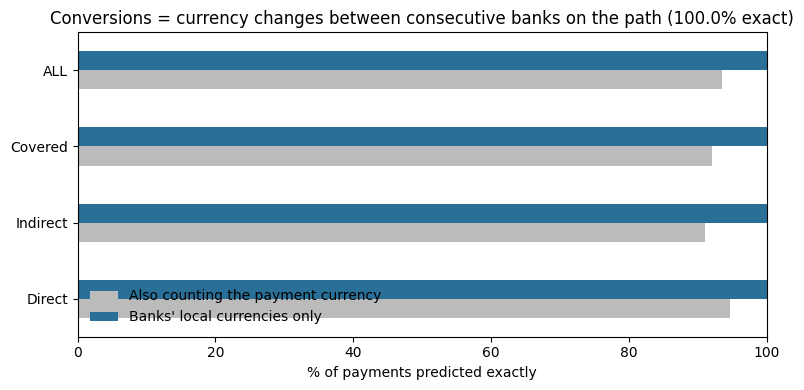

In [48]:
# Chart: accuracy of the two FX rules (baseline = rule that also counts the payment currency)
d = fx2.set_index('type')[['acc_with_payment_ccy', 'acc_banks_only']].reindex(TYPES + ['ALL']).dropna() * 100
ax = d.plot.barh(figsize=(8, 4), color=['#bbbbbb', '#2a6f97'])
ax.set_title(f'Conversions = currency changes between consecutive banks on the path ({fx_acc_alt:.1%} exact)')
ax.set_xlabel('% of payments predicted exactly'); ax.set_ylabel(''); ax.set_xlim(0, 100)
ax.legend(['Also counting the payment currency', 'Banks\' local currencies only'], frameon=False, loc='lower left')
savefig('fx2_conversion_prediction')

**Findings (FX)** (⟳ = check the printed value)
- **R-FX1 Conversions = number of times the local currency changes between consecutive banks on the path.** Exact for 100% of complete paths (1.85M rows in the 20% sample; Direct, Indirect and Covered alike). The payment currency itself is **not** counted. *Meaning:* each bank converts only when it passes the payment to a bank in a different currency zone. Extends R-CCY2 (Direct only) and R-CCY3 (conversions ≤ hops) to every routing type.
- **N-FX2 Counting the payment currency as well is wrong:** only 93.5% exact; it over-counts by exactly 1 in every error.
- **R-FX3 The path explains R-CCY2's exceptions** (⟳ `fx4`): R-CCY2 used the ordering/beneficiary BIC, but in ~5% of rows each the path starts or ends at a different bank. Using the banks actually on the path should take Direct accuracy from 97.8% to ~100%. → tell the currency teammate.
- **N-FX1 Conversions don't add time:** at the same routing type and hop count, median duration is flat across conversion counts (extra R² 0.0004).
- *Caveat:* each country's local currency is inferred from the data (the currency its senders use most), and paths with a `...` gap cannot be tested.


## Rules for this notebook
All values and verdicts are computed from the results above. Verdict scale: Confirmed (≥ 99% / effect matches) · Strong (95–99%) · Partial (70–95% or subgroup) · Rejected.
If a printed value contradicts the Findings text, update the Findings text, not the numbers.


In [49]:
dur_extra = dur_r2['extra_r2_given_type_hops']
time_extra = max(dur_extra.get('local_hour', 0), dur_extra.get('local_wd', 0))
nogap = ~rt2.path_gap
rt3_len_share = np.average(rt2.loc[nogap, 'path_len_eq_participants'], weights=rt2.loc[nogap, 'n'])
mono = all(np.all(np.diff(dur1[(dur1.TRANSACTION_TYPE_CODE == t) & (dur1.n >= 1000)].sort_values('PARTICIPANT_COUNT').med) > 0)
           for t in ['Indirect', 'Covered'])
order_ok = med_type['Direct'] < med_type['Indirect'] < med_type['Covered']
d4 = sql("SELECT anomaly, median(TOTAL_DURATION) med FROM p GROUP BY 1").set_index('anomaly').med
scam_x = {a: d4[a] / d4['NONE'] for a in ['ROMANCE_SCAM', 'CEO_SCAM', 'ACCOUNT_REPLACEMENT_SCAM'] if a in d4}
lvl = lambda x, a, b: 'Confirmed' if x <= a else 'Strong' if x <= b else 'Partial'
rules = [
    dict(id='R-RT1', group='Routing',
         rule='Direct payments involve exactly 2 banks; Indirect and Covered payments involve 3 or more',
         test='share of rows where (type = Direct) <=> (PARTICIPANT_COUNT = 2), full data',
         value=f'{rt1_share:.2%}', verdict=verdict_from_share(rt1_share),
         evidence_files='rt1_hops_by_type.csv; rt1_hops_by_type.png',
         interpretation='Direct = the two banks hold accounts with each other; otherwise correspondent banks relay the payment'),
    dict(id='R-RT6', group='Routing',
         rule=f'The number of intermediary banks is geometric: each further intermediary is added with probability q = {q_hop:.3f}; Indirect and Covered share the same hop distribution',
         test='total variation distance between observed and geometric distribution of PARTICIPANT_COUNT - 2, full data',
         value=f'q = {q_hop:.4f}; distance = {rt6_tvd:.4f}', verdict=lvl(rt6_tvd, 0.005, 0.02),
         evidence_files='rt6_intermediaries_geometric.csv; rt1_hops_by_type.csv',
         interpretation='Banks use the shortest correspondent chain available, so each extra hop is rarer'),
    dict(id='R-RT3', group='Routing',
         rule='PARTICIPANT_COUNT = number of BIC entries on the path, repeated BICs counted (complete paths)',
         test='share of rows without a path gap where path_len = PARTICIPANT_COUNT, full data',
         value=f'{rt3_len_share:.2%}', verdict=verdict_from_share(rt3_len_share),
         evidence_files='rt2_path_vs_participants.csv',
         interpretation='A bank that handles the payment twice counts twice'),
    dict(id='R-RT2', group='Routing',
         rule='The path starts at the ordering BIC and ends at the beneficiary BIC; in ~5% of rows each end is a different (usually foreign) bank',
         test='share of rows, full data, every routing type', value=f'start {rt2_start:.2%}; end {rt2_end:.2%}',
         verdict=verdict_from_share(min(rt2_start, rt2_end)),
         evidence_files='rt2_path_vs_participants.csv; rt2_first_bank_mismatch.csv; rt2_currency_vs_first_bank.csv',
         interpretation='A parent/branch BIC or an outsourced sending/receiving bank processes the payment'),
    dict(id='R-RT5', group='Routing',
         rule=f"Each link between consecutive banks independently has a {q_link:.1%} chance of a continuity gap ('...')",
         test='largest absolute error between observed gap rate and 1-(1-q)^(participants-1), groups with >= 1000 rows',
         value=f'{rt5_maxerr:.4f}', verdict=lvl(rt5_maxerr, 0.005, 0.01),
         evidence_files='rt5_gap_by_participants.csv',
         interpretation='Longer chains have more hand-overs where tracking can break'),
    dict(id='R-RT7', group='Routing',
         rule='Routing type is independent of the business/consumer pair',
         test="Cramér's V (routing type x pair), full data", value=f"V = {rt4_v['pair']:.4f}",
         verdict='Confirmed' if rt4_v['pair'] < 0.01 else 'Rejected',
         evidence_files='rt4_type_by_pair.csv',
         interpretation='Routing depends on the banks, not on who the customers are'),
    dict(id='R-RT8', group='Routing',
         rule='Domestic payments are routed Covered more often than cross-border ones; the Direct share is the same',
         test="Covered share domestic vs cross-border; Cramér's V, full data",
         value=f"Covered {cov_dom:.2f}% vs {cov_xb:.2f}%; V = {rt4_v['cross_border']:.4f}",
         verdict='Confirmed' if cov_dom > 1.5 * cov_xb else 'Rejected',
         evidence_files='rt4_type_by_cross_border.csv',
         interpretation='Counter-intuitive (cover payments are normally cross-border): likely a feature of how the data was generated'),
    dict(id='R-DUR1', group='Duration',
         rule='Duration is set by routing: Direct < Indirect < Covered, and every extra bank adds time',
         test='median duration by type and hop count (normal rows, full data); R² of ln(duration) on type + hops (20% sample)',
         value='medians ' + ', '.join(f'{t} {med_type.get(t, np.nan):.0f}s' for t in TYPES) + f'; R² {r2_base:.3f} (noisy)',
         verdict='Confirmed' if (mono and order_ok) else 'Partial',
         evidence_files='dur1_by_type_hops.csv; dur1_by_type_hops.png; dur2_factor_screening.csv',
         interpretation='Each correspondent bank adds processing and queueing time'),
    dict(id='R-DUR2', group='Duration',
         rule="Sender and receiver country each add their own delay, about as much as routing does",
         test='R² of ln(duration) on sender + receiver country, Direct payments only (additive, 20% sample)',
         value=f"sender {dur_cc['sender country']:.3f}; receiver {dur_cc['receiver country']:.3f}; both {dur_cc['sender + receiver (additive)']:.3f}",
         verdict='Confirmed' if dur_cc['sender + receiver (additive)'] >= 0.01 else 'Rejected',
         evidence_files='dur2_factor_screening.csv; dur2_country_speed_direct.csv',
         interpretation="Each country's banks have their own processing speed (cut-off times, compliance checks)"),
    dict(id='R-DUR3', group='Duration',
         rule='Scam payments (romance, CEO, account replacement) take 10-20x longer than normal; fat-finger and recall payments do not',
         test='median duration vs normal payments, full data', value='; '.join(f'{k} x{v:.1f}' for k, v in scam_x.items()),
         verdict='Confirmed' if scam_x and min(scam_x.values()) >= 5 else 'Partial',
         evidence_files='dur4_by_anomaly.csv',
         interpretation='Suspicious payments are held for screening before release (share with anomalies)'),
    dict(id='N-DUR1', group='Duration',
         rule='Sender-local hour / weekday changes duration',
         test='extra R² of ln(duration) beyond type + hops', value=f'hour {dur_extra.get("local_hour", np.nan):.4f}; weekday {dur_extra.get("local_wd", np.nan):.4f}',
         verdict='Rejected' if time_extra < 0.003 else 'Partial',
         evidence_files='dur3_by_local_hour.csv; dur3_by_local_weekday.csv; dur3_by_local_hour.png',
         interpretation='Processing time does not depend on when the payment is sent'),
    dict(id='R-FX1', group='FX',
         rule='Conversions = number of local-currency changes between consecutive banks on the path (payment currency not counted)',
         test='exact prediction accuracy, 20% sample, paths without a gap', value=f'{fx_acc_alt:.2%}',
         verdict=verdict_from_share(fx_acc_alt),
         evidence_files='fx2_conversion_prediction.csv; fx2_conversion_prediction.png',
         interpretation='Each bank converts only when it hands the payment to a bank in another currency zone; extends R-CCY2 and R-CCY3'),
    dict(id='N-FX2', group='FX',
         rule='Conversions also count the change from the payment currency to the first bank',
         test='exact prediction accuracy, same rows', value=f'{fx_acc:.2%} (always over-counts by 1)',
         verdict='Rejected', evidence_files='fx2_conversion_prediction.csv; fx2_prediction_errors.csv',
         interpretation='The first bank does not convert the payment currency'),
    dict(id='R-FX3', group='FX',
         rule='R-CCY2 exceptions disappear when the banks actually on the path are used instead of the ordering/beneficiary BIC',
         test='accuracy on all Direct rows, full data', value=f'path banks {fx4_new:.2%} vs ordering/beneficiary {fx4_old:.2%}',
         verdict=verdict_from_share(fx4_new),
         evidence_files='fx4_rccy2_exceptions.csv',
         interpretation='Conversions follow the banks that process the payment (see R-RT2)'),
    dict(id='N-FX1', group='FX',
         rule='At the same routing and hop count, extra conversions add duration',
         test='extra R² of conversions on ln(duration) given type + hops', value=f'{fx_dur_extra:.4f}',
         verdict='Rejected' if fx_dur_extra < 0.003 else 'Partial',
         evidence_files='fx3_duration_by_conversions.csv',
         interpretation='Duration is driven by the number of banks, not by FX'),
]
pd.DataFrame(rules, columns=RULE_COLS).to_csv(RULES / 'rules_02.csv', index=False)
log = combine_rules()
log.loc[log.source == 'rules_02.csv', ['id', 'group', 'value', 'verdict']]

,id,group,value,verdict
0,R-RT1,Routing,100.00%,Confirmed
1,R-RT6,Routing,q = 0.3677; distance = 0.0001,Confirmed
2,R-RT3,Routing,100.00%,Confirmed
3,R-RT2,Routing,start 95.02%; end 95.01%,Strong
4,R-RT5,Routing,0.0139,Partial
5,R-RT7,Routing,V = 0.0024,Confirmed
6,R-RT8,Routing,Covered 7.34% vs 3.92%; V = 0.0459,Confirmed
7,R-DUR1,Duration,"medians Direct 39s, Indirect 281s, Covered 383...",Confirmed
8,R-DUR2,Duration,sender 0.051; receiver 0.047; both 0.091,Confirmed
9,R-DUR3,Duration,ROMANCE_SCAM x20.5; CEO_SCAM x13.2; ACCOUNT_RE...,Confirmed



## Power BI hand-off
Import these CSVs from `outputs/tables/` (all small; keep the column names exactly as they are):

| Page | Files | Rules |
|---|---|---|
| Routing | `rt1_hops_by_type`, `rt6_intermediaries_geometric`, `rt2_path_vs_participants`, `rt5_gap_by_participants`, `rt4_type_by_pair`, `rt4_type_by_cross_border` | R-RT1, R-RT6, R-RT3, R-RT2, R-RT5, R-RT7, R-RT8 |
| Duration | `dur1_by_type_hops`, `dur2_country_speed_direct`, `dur4_by_anomaly`, `dur3_by_local_hour` | R-DUR1, R-DUR2, R-DUR3, N-DUR1 |
| FX | `fx2_conversion_prediction`, `fx4_rccy2_exceptions`, `fx3_duration_by_conversions` | R-FX1, N-FX2, R-FX3, N-FX1 |

Each page: a text box with the rule + its value from `rules_02.csv`, one chart per rule against a baseline, and a takeaway title.
